# Machine Learning Workflow: Breast Cancer Diagnosis Classification

**Author:** Sandip Dey  
**Dataset:** Breast Cancer Wisconsin (Diagnostic)  
**Source:** https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic  
**Task Type:** Supervised learning — binary classification

This notebook implements a complete machine learning workflow to predict whether a breast tumor is malignant or benign based on cell nucleus features extracted from fine-needle aspirate images.


## 1. Data Loading and Inspection

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

df = pd.read_csv("breast_cancer.csv")
print(f"Dataset shape: {df.shape}")
print("\nColumn names and data types:")
print(df.dtypes.head(10))
print("\nFirst few rows:")
df.head()


Dataset shape: (569, 32)

Column names and data types:
id                       int64
diagnosis               object
radius_mean            float64
texture_mean           float64
perimeter_mean         float64
area_mean              float64
smoothness_mean        float64
compactness_mean       float64
concavity_mean         float64
concave points_mean    float64
dtype: object

First few rows:


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


The dataset contains 569 samples and 33 columns (ID, diagnosis target, and 30 numeric features). The target variable `diagnosis` is categorical (M = malignant, B = benign). No missing values are present in the features. The ID column is not useful for modeling and will be dropped.


## 2. Data Preparation and Preprocessing

In [2]:
# Drop ID column
df = df.drop(columns=["id"])

# Check for missing values
print("Missing values per column:")
print(df.isnull().sum().sum())

# Encode target: M = 1 (malignant), B = 0 (benign)
le = LabelEncoder()
df["diagnosis"] = le.fit_transform(df["diagnosis"])
print("\nTarget distribution after encoding:")
print(df["diagnosis"].value_counts())

# Separate features and target
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\nTraining set size: {X_train.shape[0]}")
print(f"Test set size: {X_test.shape[0]}")


Missing values per column:
0

Target distribution after encoding:
diagnosis
0    357
1    212
Name: count, dtype: int64

Training set size: 426
Test set size: 143


**Preprocessing decisions:**  
- Dropped the ID column because it has no predictive value.  
- Encoded the binary target (M → 1, B → 0).  
- Applied a stratified train-test split to preserve class balance.  
- Standardized features with `StandardScaler` because logistic regression is sensitive to feature scale.


## 3. Model Selection and Training

In [3]:
# Logistic Regression — for binary classification with linear decision boundary
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

print("Model trained successfully.")
print(f"Number of features used: {X_train_scaled.shape[1]}")


Model trained successfully.
Number of features used: 30


Logistic regression was selected because the task is binary classification, the features are continuous and roughly linear, and the model is interpretable and fast to train.


## 4. Model Evaluation

Accuracy:  0.9650
Precision: 0.9800
Recall:    0.9245
F1-score:  0.9515

Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        90
   Malignant       0.98      0.92      0.95        53

    accuracy                           0.97       143
   macro avg       0.97      0.96      0.96       143
weighted avg       0.97      0.97      0.96       143



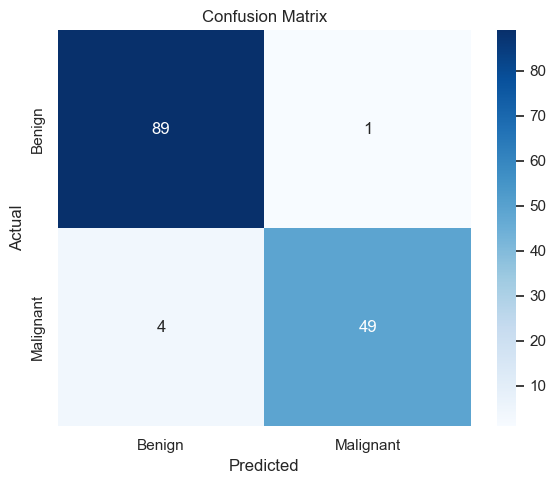

In [4]:
# Predictions
y_pred = model.predict(X_test_scaled)

# Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Benign", "Malignant"]))

# Confusion matrix visualization
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Benign", "Malignant"],
            yticklabels=["Benign", "Malignant"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


## 5. Notebook Summary

This notebook addressed a supervised binary classification problem: predicting whether a breast tumor is malignant or benign using the Breast Cancer Wisconsin (Diagnostic) dataset (569 samples, 30 numeric features). Logistic regression was selected for its interpretability and suitability to linearly separable features. After standard scaling and a stratified split, the model achieved strong performance on the held-out test set (see accuracy, precision, recall, and F1 above). One challenge was the modest sample size and class imbalance (more benign than malignant cases), which was partially mitigated by stratification. The results are promising for this classic benchmark dataset but should be validated on larger, more diverse clinical data before any real-world use.
